In [245]:
import pandas as pd 
import matplotlib.pyplot as plt
from sklearn.preprocessing import RobustScaler,StandardScaler,PolynomialFeatures
from sklearn.linear_model import LinearRegression , SGDRegressor , Ridge , Lasso
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error , mean_absolute_error
from scipy.stats import pearsonr
import numpy as np
import seaborn as sns
import math


In [95]:
df = pd.read_csv("C:/Users/leste/OneDrive/Desktop/Microsoft VS Code/Github/Data-Science-Portfolio/Data Files/Multiple Regression methods/Concrete_Data.csv")

In [96]:
df

,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30
...,...,...,...,...,...,...,...,...,...
1025,276.4,116.0,90.3,179.6,8.9,870.1,768.3,28,44.28
1026,322.2,0.0,115.6,196.0,10.4,817.9,813.4,28,31.18
1027,148.5,139.4,108.6,192.7,6.1,892.4,780.0,28,23.70
1028,159.1,186.7,0.0,175.6,11.3,989.6,788.9,28,32.77


In [97]:
df.columns

Index(['Cement (component 1)(kg in a m^3 mixture)',
       'Blast Furnace Slag (component 2)(kg in a m^3 mixture)',
       'Fly Ash (component 3)(kg in a m^3 mixture)',
       'Water  (component 4)(kg in a m^3 mixture)',
       'Superplasticizer (component 5)(kg in a m^3 mixture)',
       'Coarse Aggregate  (component 6)(kg in a m^3 mixture)',
       'Fine Aggregate (component 7)(kg in a m^3 mixture)', 'Age (day)',
       'Concrete compressive strength(MPa, megapascals) '],
      dtype='str')

In [98]:
columns_renamed = {
    'Cement (component 1)(kg in a m^3 mixture)' : 'Cement',
    'Blast Furnace Slag (component 2)(kg in a m^3 mixture)' : 'Blast Furnace Slag',
    'Fly Ash (component 3)(kg in a m^3 mixture)': 'Fly Ash',
    'Water  (component 4)(kg in a m^3 mixture)': 'Water',
    'Superplasticizer (component 5)(kg in a m^3 mixture)' : 'Superplasticizer',
    'Coarse Aggregate  (component 6)(kg in a m^3 mixture)': 'Coarse Aggregate',
    'Fine Aggregate (component 7)(kg in a m^3 mixture)' : 'Fine Aggregate', 
    'Age (day)' : 'Age-day',
    'Concrete compressive strength(MPa, megapascals) ' : 'CCS'
}

In [99]:
df.rename(columns = columns_renamed, inplace = True)

C:\Users\leste\AppData\Local\Temp\ipykernel_16768\3187779234.py:1: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.rename(columns = columns_renamed, inplace = True)


In [100]:
concrete_data = df.copy()

In [101]:
concrete_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Cement              1030 non-null   float64
 1   Blast Furnace Slag  1030 non-null   float64
 2   Fly Ash             1030 non-null   float64
 3   Water               1030 non-null   float64
 4   Superplasticizer    1030 non-null   float64
 5   Coarse Aggregate    1030 non-null   float64
 6   Fine Aggregate      1030 non-null   float64
 7   Age-day             1030 non-null   int64  
 8   CCS                 1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB


In [102]:
concrete_data

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age-day,CCS
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30
...,...,...,...,...,...,...,...,...,...
1025,276.4,116.0,90.3,179.6,8.9,870.1,768.3,28,44.28
1026,322.2,0.0,115.6,196.0,10.4,817.9,813.4,28,31.18
1027,148.5,139.4,108.6,192.7,6.1,892.4,780.0,28,23.70
1028,159.1,186.7,0.0,175.6,11.3,989.6,788.9,28,32.77


> Concrete compressive strength being the target `y` variable

<Axes: xlabel='CCS'>

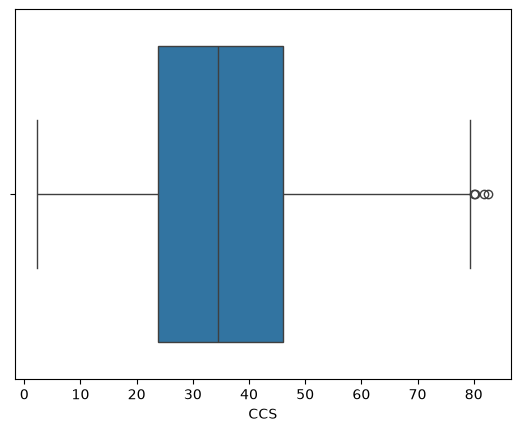

In [103]:
sns.boxplot(x = concrete_data['CCS'])

<Axes: xlabel='CCS', ylabel='Count'>

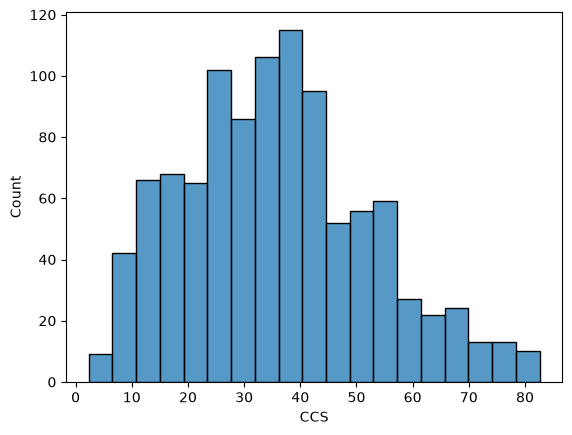

In [104]:
sns.histplot(x = concrete_data['CCS'])

Text(0.5, 0, 'Age vs CCS')

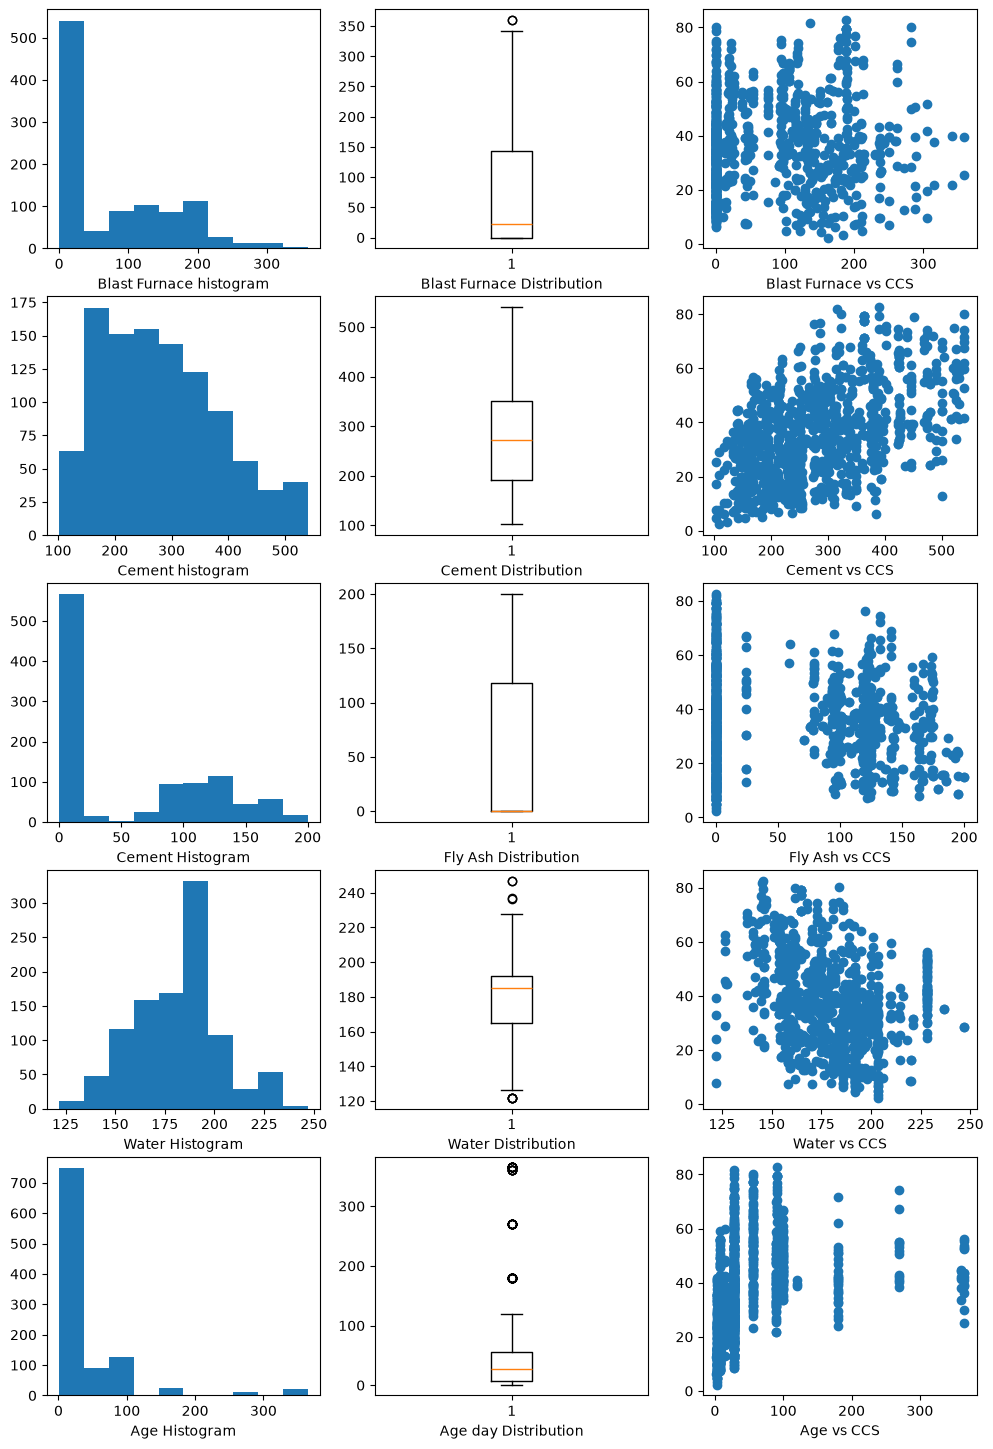

In [105]:
fig, ax = plt.subplots(5,3, figsize = (12,18))

ax[0,0].hist(x = concrete_data['Blast Furnace Slag'])
ax[0,0].set_xlabel('Blast Furnace histogram')

ax[0,1].boxplot(x = concrete_data['Blast Furnace Slag'])
ax[0,1].set_xlabel("Blast Furnace Distribution")

ax[0,2].scatter(x = concrete_data['Blast Furnace Slag'] , y = concrete_data['CCS'])
ax[0,2].set_xlabel("Blast Furnace vs CCS")

ax[1,0].hist(x = concrete_data['Cement'])
ax[1,0].set_xlabel('Cement histogram')

ax[1,1].boxplot(x = concrete_data['Cement'])
ax[1,1].set_xlabel("Cement Distribution")

ax[1,2].scatter(x = concrete_data['Cement'] , y = concrete_data['CCS'])
ax[1,2].set_xlabel("Cement vs CCS")

ax[2,0].hist(x = concrete_data['Fly Ash'])
ax[2,0].set_xlabel("Cement Histogram")

ax[2,1].boxplot(x = concrete_data['Fly Ash'])
ax[2,1].set_xlabel("Fly Ash Distribution")

ax[2,2].scatter(x = concrete_data['Fly Ash'], y = concrete_data['CCS'])
ax[2,2].set_xlabel("Fly Ash vs CCS")

ax[3,0].hist(x = concrete_data['Water'])
ax[3,0].set_xlabel("Water Histogram")

ax[3,1].boxplot(x = concrete_data['Water'])
ax[3,1].set_xlabel("Water Distribution")

ax[3,2].scatter(x = concrete_data['Water'], y = concrete_data['CCS'])
ax[3,2].set_xlabel("Water vs CCS")

ax[4,0].hist(x = concrete_data['Age-day'])
ax[4,0].set_xlabel("Age Histogram")

ax[4,1].boxplot(x = concrete_data['Age-day'])
ax[4,1].set_xlabel("Age day Distribution")

ax[4,2].scatter(x = concrete_data['Age-day'], y = concrete_data['CCS'])
ax[4,2].set_xlabel("Age vs CCS")

<Axes: >

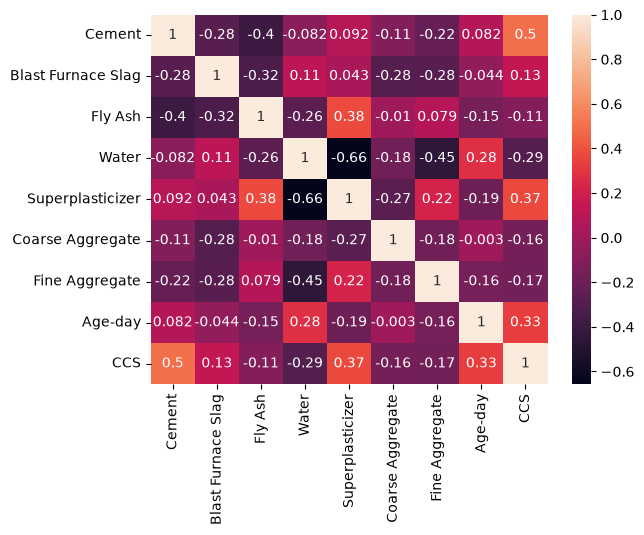

In [106]:
sns.heatmap(concrete_data.corr(), annot = True)

> Cement has the highest correlation with CCS


### Feature Selection

> Robust Scaling with features having outliers 

> Features like Age-day , Water , Blast Furnace have extreme outliers which can't be scaled by Standard scaler by default as values can be heavilly affected by outliers

> Features like Fly Ash & Cement can be normalized using Standard scaling

In [107]:
robust = RobustScaler() #by default median and IQR is true
stand = StandardScaler() #by default mean and std is true

In [108]:
x_features_robust = robust.fit_transform(concrete_data[['Age-day','Water','Blast Furnace Slag']])
x_features_stand = stand.fit_transform(concrete_data[['Fly Ash','Cement']])

In [109]:
x_features = np.hstack([x_features_robust,x_features_stand])
y_features = stand.fit_transform(concrete_data[['CCS']])

> Multivariate Regression using simple Linear Regression Model

In [110]:
x_train , x_temp , y_train , y_temp = train_test_split(x_features,y_features, test_size = 0.2 , random_state = 42) 
x_val , x_test , y_val , y_test = train_test_split(x_temp,y_temp , test_size = 0.4 , random_state = 42)

In [111]:
# Shape of the Dataset 
print(x_train.shape)
print(x_temp.shape)
print(x_val.shape)
print(x_test.shape)

(824, 5)
(206, 5)
(123, 5)
(83, 5)


In [ ]:

linear_model = LinearRegression()

In [132]:
linear_model.fit(x_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 5)","[[ 0.34,-0.41, 0.82, 0.28, 0.67]]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[-0.47]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(5)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](5,)","[38.21,32.45,26.66,19.65,12.4 ]"


In [ ]:
linear_w_params = linear_model.coef_
linear_b_params = linear_model.intercept_

In [ ]:
y_multi_pred_val = model.predict(x_val) 
y_multi_pred_test = model.predict(x_test)

In [ ]:
linear_mse = mean_squared_error(y_multi_pred_val,y_val)
linear_mae = mean_absolute_error(y_multi_pred_val, y_val)


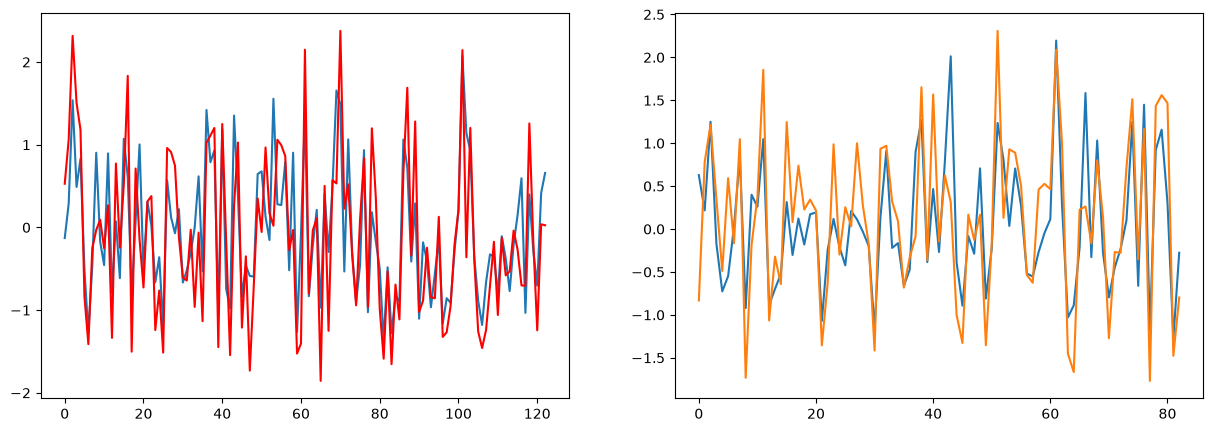

In [ ]:
fig , ax = plt.subplots(1,2, figsize = (15,5))

ax[0].plot(np.arange(len(y_multi_pred_val)), y_multi_pred_val)
ax[0].plot(np.arange(len(y_val)), y_val, color = 'red')

ax[1].plot(np.arange(len(y_multi_pred_test)),y_multi_pred_test)
ax[1].plot(np.arange(len(y_test)),y_test)


In [142]:
linear_model_val_score = linear_model.score(x_val,y_val)

In [144]:
linear_model_train_score = linear_model.score(x_train,y_train)
linear_model_train_score

0.6045119192227095

In [145]:
print(f"The Mean Squared error for {type(linear_model).__name__} is {linear_mse}")
print(f"The Mean Absolute error for {type(linear_model).__name__} is {linear_mae}")
print(f"The r2 score of the Accuracy for validation {type(linear_model).__name__} is {linear_model_val_score}")
print(f"The w values & b constant value for {type(linear_model).__name__} is {w_params} & {b_params}")

The Mean Squared error for LinearRegression is 0.3461135391688069
The Mean Absolute error for LinearRegression is 0.4660675230456998
The r2 score of the Accuracy for validation LinearRegression is 0.6328196025481205
The w values & b constant value for LinearRegression is [[ 0.34016653 -0.40546923  0.81793455  0.27612133  0.67377099]] & [-0.47056905]


### Implementing SGDRegressor optimization algorithm

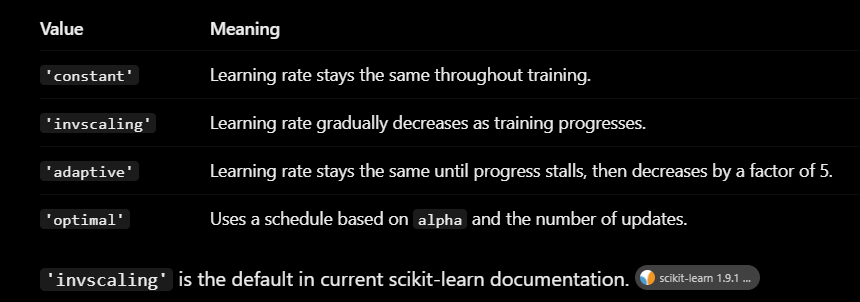

In [190]:
Gd_model = SGDRegressor(
    max_iter = 1000,
    loss = 'squared_error', #loss function
    learning_rate = 'adaptive',
    penalty = 'l1', # used for determining the behaviour of the learning rate
    eta0 = 0.01
)

In [191]:
Gd_model.fit(x_train,y_train)

c:\Users\leste\OneDrive\Desktop\Microsoft VS Code\Github\Data-Science-Portfolio\.venv\Lib\site-packages\sklearn\utils\validation.py:1368: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


,"penalty penalty: {'l2', 'l1', 'elasticnet', None}, default='l2'The penalty (aka regularization term) to be used. Defaults to 'l2'which is the standard regularizer for linear SVM models. 'l1' and'elasticnet' might bring sparsity to the model (feature selection)not achievable with 'l2'. No penalty is added when set to `None`.You can see a visualisation of the penalties in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_penalties.py`.",'l1'
,"learning_rate learning_rate: str, default='invscaling'The learning rate schedule:- 'constant': `eta = eta0`- 'optimal': `eta = 1.0 / (alpha * (t + t0))` where t0 is chosen by a heuristic proposed by Leon Bottou.- 'invscaling': `eta = eta0 / pow(t, power_t)`- 'adaptive': eta = eta0, as long as the training keeps decreasing. Each time n_iter_no_change consecutive epochs fail to decrease the training loss by tol or fail to increase validation score by tol if early_stopping is True, the current learning rate is divided by 5.- 'pa1': passive-aggressive algorithm 1, see [1]_. Only with `loss='epsilon_insensitive'`. Update is `w += eta y x` with `eta = min(eta0, loss/||x||**2)`.- 'pa2': passive-aggressive algorithm 2, see [1]_. Only with `loss='epsilon_insensitive'`. Update is `w += eta y x` with `eta = hinge_loss / (||x||**2 + 1/(2 eta0))`... versionadded:: 0.20 Added 'adaptive' option... versionadded:: 1.8 Added options 'pa1' and 'pa2'",'adaptive'
,"loss loss: str, default='squared_error'The loss function to be used. The possible values are 'squared_error','huber', 'epsilon_insensitive', or 'squared_epsilon_insensitive'The 'squared_error' refers to the ordinary least squares fit.'huber' modifies 'squared_error' to focus less on getting outlierscorrect by switching from squared to linear loss past a distance ofepsilon. 'epsilon_insensitive' ignores errors less than epsilon and islinear past that; this is the loss function used in SVR.'squared_epsilon_insensitive' is the same but becomes squared loss pasta tolerance of epsilon.More details about the losses formulas can be found in the:ref:`User Guide <sgd_mathematical_formulation>`.",'squared_error'
,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term. The higher thevalue, the stronger the regularization. Also used to compute thelearning rate when `learning_rate` is set to 'optimal'.Values must be in the range `[0.0, inf)`.",0.0001
,"l1_ratio l1_ratio: float, default=0.15The Elastic Net mixing parameter, with 0 <= l1_ratio <= 1.l1_ratio=0 corresponds to L2 penalty, l1_ratio=1 to L1.Only used if `penalty` is 'elasticnet'.Values must be in the range `[0.0, 1.0]` or can be `None` if`penalty` is not `elasticnet`... versionchanged:: 1.7 `l1_ratio` can be `None` when `penalty` is not ""elasticnet"".",0.15
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If False, thedata is assumed to be already centered.",True
,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method.Values must be in the range `[1, inf)`... versionadded:: 0.19",1000
,"tol tol: float or None, default=1e-3The stopping criterion. If it is not None, training will stopwhen (loss > best_loss - tol) for ``n_iter_no_change`` consecutiveepochs.Convergence is checked against the training loss or thevalidation loss depending on the `early_stopping` parameter.Values must be in the range `[0.0, inf)`... versionadded:: 0.19",0.001
,"shuffle shuffle: bool, default=TrueWhether or not the training data should be shuffled after each epoch.",True
,"verbose verbose: int, default=0The verbosity level.Values must be in the range `[0, inf)`.",0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-insensitive loss functions; only if `loss` is'huber', 'epsilon_insensitive', or 'squared_epsilon_insensitive'.For 'huber', determines the threshold at which it becomes lessimportant to get th

In [192]:
Gd_w_params = Gd_model.coef_
Gd_b_params = Gd_model.intercept_

In [193]:
y_gd_pred_val = Gd_model.predict(x_val)
y_gd_pred_test = Gd_model.predict(x_test)

In [194]:
Gd_model_mse = mean_squared_error(y_val,y_gd_pred_val)
Gd_model_mae = mean_absolute_error(y_test,y_gd_pred_test)
Gd_model_train_score = Gd_model.score(x_train,y_train)
Gd_model_val_score = Gd_model.score(x_val,y_val)

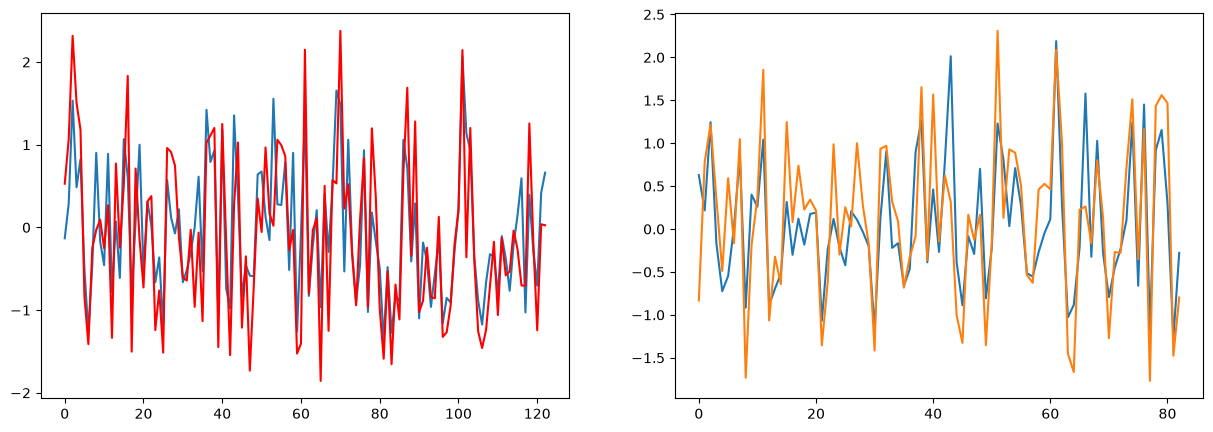

In [195]:
fig , ax = plt.subplots(1,2, figsize = (15,5))

ax[0].plot(np.arange(len(y_gd_pred_val)), y_gd_pred_val)
ax[0].plot(np.arange(len(y_val)), y_val, color = 'red')

ax[1].plot(np.arange(len(y_gd_pred_test)),y_gd_pred_test)
ax[1].plot(np.arange(len(y_test)),y_test)


In [196]:
print(f"The Mean Squared error for {type(Gd_model).__name__} is {Gd_model_mse}")
print(f"The Mean Absolute error for {type(Gd_model).__name__} is {Gd_model_mae}")
print(f"The r2 score of the Accuracy for Training {type(Gd_model).__name__} is {Gd_model_train_score}")
print(f"The r2 score of the Accuracy for Validation {type(Gd_model).__name__} is {Gd_model_val_score}")
print(f"The w values & b constant value for {type(Gd_model).__name__} is {Gd_w_params} & {Gd_b_params}")

The Mean Squared error for SGDRegressor is 0.34685807873697905
The Mean Absolute error for SGDRegressor is 0.45404757346073915
The r2 score of the Accuracy for Training SGDRegressor is 0.6045035352768364
The r2 score of the Accuracy for Validation SGDRegressor is 0.6320297451642787
The w values & b constant value for SGDRegressor is [ 0.33965136 -0.4029139   0.81639403  0.27429969  0.67191736] & [-0.46941525]


### Polynomial Regression

In [219]:
poly_model = make_pipeline(
    PolynomialFeatures(degree = 2),
    Ridge(alpha = 0.001)

    )

In [220]:
poly_model.fit(x_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('polynomialfeatures', ...), ('ridge', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"degree degree: int or tuple (min_degree, max_degree), default=2If a single int is given, it specifies the maximal degree of thepolynomial features. If a tuple `(min_degree, max_degree)` is passed,then `min_degree` is the minimum and `max_degree` is the maximumpolynomial degree of the generated features. Note that `min_degree=0`and `min_degree=1` are equivalent as outputting the degree zero term isdetermined by `include_bias`.",2
,"interaction_only interaction_only: bool, default=FalseIf `True`, only interaction features are produced: features that areproducts of at most `degree` *distinct* input features, i.e. terms withpower of 2 or higher of the same input feature are excluded:- included: `x[0]`, `x[1]`, `x[0] * x[1]`, etc.- excluded: `x[0] ** 2`, `x[0] ** 2 * x[1]`, etc.",False
,"include_bias include_bias: bool, default=TrueIf `True` (default), then include a bias column, the feature in whichall polynomial powers are zero (i.e. a column of ones - acts as anintercept term in a linear model).",True
,"order order: {'C', 'F'}, default='C'Order of output array in the dense case. `'F'` order is faster tocompute, but may slow down subsequent estimators... versionadded:: 0.21",'C'
Name,Type,Value


In [211]:
poly_model.score(x_train,y_train)

0.7682349669573938

In [242]:
poly_w_params = poly_model.named_steps['ridge'].coef_
poly_b_params = poly_model.named_steps['ridge'].intercept_

In [213]:
y_poly_pred_val = poly_model.predict(x_val)
y_poly_pred_test = poly_model.predict(x_test)

In [214]:
poly_model_mse = mean_squared_error(y_val,y_poly_pred_val)
poly_model_mae = mean_absolute_error(y_test,y_poly_pred_test)
poly_model_train_score = poly_model.score(x_train,y_train)
poly_model_val_score = poly_model.score(x_val,y_val)

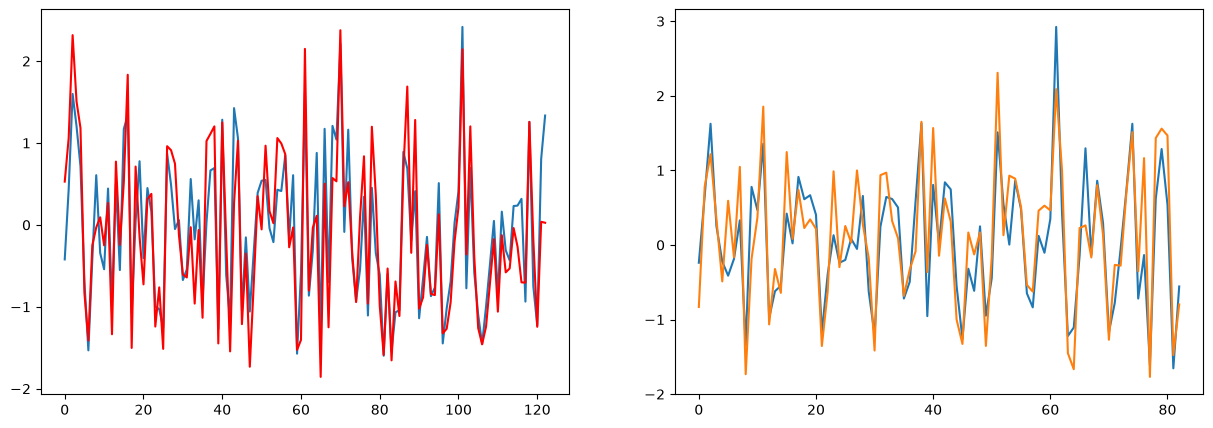

In [215]:
fig , ax = plt.subplots(1,2, figsize = (15,5))

ax[0].plot(np.arange(len(y_poly_pred_val)), y_poly_pred_val)
ax[0].plot(np.arange(len(y_val)), y_val, color = 'red')

ax[1].plot(np.arange(len(y_poly_pred_test)),y_poly_pred_test)
ax[1].plot(np.arange(len(y_test)),y_test)

In [243]:
print(f"The Mean Squared error for {type(poly_model).__name__} is {poly_model_mse}")
print(f"The Mean Absolute error for {type(poly_model).__name__} is {poly_model_mae}")
print(f"The r2 score of the Accuracy for Training {type(poly_model).__name__} is {poly_model_train_score}")
print(f"The r2 score of the Accuracy for Validation {type(poly_model).__name__} is {poly_model_val_score}")
print(f"The w values & b constant value for {type(poly_model).__name__} is {poly_w_params} & {poly_b_params}")

The Mean Squared error for Pipeline is 0.2154700979240501
The Mean Absolute error for Pipeline is 0.3769712218841174
The r2 score of the Accuracy for Training Pipeline is 0.7682349669573938
The r2 score of the Accuracy for Validation Pipeline is 0.7714149051067275
The w values & b constant value for Pipeline is [ 0.00000000e+00  8.83760604e-01 -2.67094918e-01  1.09297943e+00
  3.61887491e-01  7.55016496e-01 -9.70057293e-02 -6.01880993e-02
  1.27969849e-01  1.23093579e-01  6.77593513e-03  3.64508009e-03
 -1.04848817e-01  2.19883982e-04 -5.56610910e-02 -2.88490641e-01
 -1.17820766e-01 -1.19497819e-01 -1.29593507e-01 -8.18644843e-02
 -8.78996470e-02] & [-0.27247373]


### Checking K-Fold Scores across the models
